In [1]:
import discretisedfield as df
import micromagneticmodel as mm
import oommfc as mc

In [2]:
system = mm.System(name="thetaevolve", T=60)

In [3]:
mesh = df.Mesh(p1=(0, 0, 0), p2=(1e-7, 1e-7, 1e-9), cell=(1e-9, 1e-9, 1e-9))
system.m = df.Field(mesh, nvdim=3, value=(1, 0, 0), norm=1700e3)

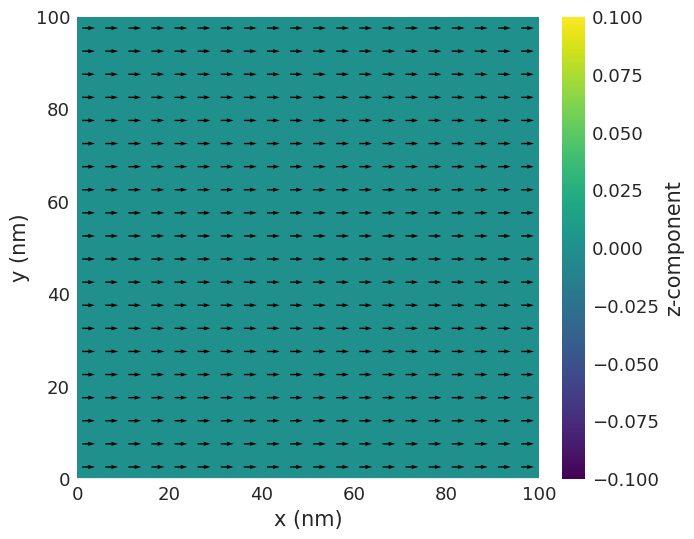

In [4]:
system.m.sel("z").resample(n=(20, 20)).mpl()

In [6]:
system.dynamics = mm.Damping(alpha=0.1) + mm.Precession(gamma0=mm.consts.gamma0)
system.dynamics

Damping(alpha=0.1) + Precession(gamma0=221276.14872118403)

In [5]:
system.energy = mm.Exchange(A=1e-12)

In [7]:
system.energy

Exchange(A=1e-12)

In [7]:
evolver = mc.UHH_ThetaEvolver(fixed_timestep=2e-13)

In [8]:
td = mc.TimeDriver(evolver=evolver)

In [9]:
td.drive(system, t=5e-10, n=50)

Running OOMMF (ExeOOMMFRunner)[2026-10-25T22:06:18]... (2.9 s)


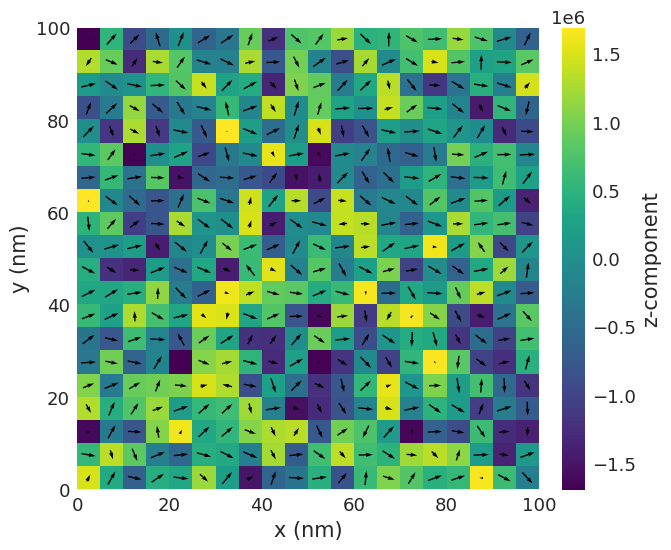

In [10]:
system.m.sel("z").resample(n=(20, 20)).mpl()

In [11]:
system.table.data.head()

,E,E_calc_count,max_dmdt,dE/dt,delta_E,T,E_exchange,max_spin_ang_exchange,stage_max_spin_ang_exchange,run_max_spin_ang_exchange,iteration,stage_iteration,stage,mx,my,mz,last_time_step,t
0,1.120473e-17,51.0,94556.924744,-0.000002,1.424474e-19,60.0,1.120473e-17,139.657090,139.657090,139.657090,50.0,50.0,0.0,0.858284,-0.000984,0.004200,2.000000e-13,1.000000e-11
1,1.659172e-17,102.0,111424.756023,-0.000002,7.302315e-20,60.0,1.659172e-17,165.993223,177.321519,177.321519,101.0,50.0,1.0,0.779396,-0.000714,0.008684,2.000000e-13,2.000000e-11
2,1.886557e-17,153.0,97915.624174,-0.000002,3.477843e-20,60.0,1.886557e-17,170.565176,177.967891,177.967891,152.0,50.0,2.0,0.738897,0.000991,0.004611,2.000000e-13,3.000000e-11
3,2.001070e-17,204.0,97996.465424,-0.000002,3.091047e-20,60.0,2.001070e-17,176.614042,179.480712,179.480712,203.0,50.0,3.0,0.714047,-0.002506,0.006134,2.000000e-13,4.000000e-11
4,2.038523e-17,255.0,97941.958430,-0.000002,3.478005e-20,60.0,2.038523e-17,175.466903,179.097395,179.480712,254.0,50.0,4.0,0.700108,-0.004356,0.002749,2.000000e-13,5.000000e-11


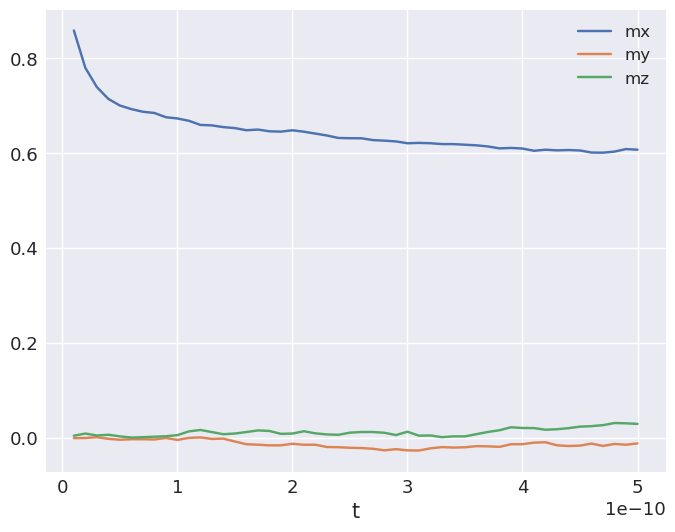

In [12]:
system.table.data.plot(x="t", y=["mx", "my", "mz"], grid=True);